# Noisy circuit visualization

`examples/multi_round/d3_reuse1_3rounds/noisy_perop.stim` から最初の数 stab を切り出し、Stim の `timeline-svg` で描画する。

ノイズモデル: PAULI_CHANNEL_2 (lookup table, strict) + idle dephasing + per-op transport Z_ERROR

出力 SVG は `examples/multi_round/d3_reuse1_3rounds/diagrams/` に保存。

## 描画する stab
- **weight 2 Z-stab (Z03)**: 1 番目の stab。最小構成 (RESET + CX×2 + MEASURE + DETECTOR)。
- **weight 4 Z-stab (Z1245)**: 3 番目の stab。重み 4 のスケール感を見る用 (RESET + CX×4 + MEASURE + DETECTOR)。

両方とも Z-type なので DETECTOR が出る (round 1, 初期 \|0\rangle 状態に対して `DETECTOR rec[-1]`)。

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO / 'src'))

import stim
from IPython.display import SVG, display

CIRCUIT_PATH = REPO / 'examples' / 'multi_round' / 'd3_reuse1_3rounds' / 'noisy_perop.stim'
DIAGRAMS_DIR = REPO / 'examples' / 'multi_round' / 'd3_reuse1_3rounds' / 'diagrams'
DIAGRAMS_DIR.mkdir(parents=True, exist_ok=True)

circuit = stim.Circuit.from_file(str(CIRCUIT_PATH))
print(f'Loaded: {CIRCUIT_PATH.name}')
print(f'  total instructions: {len(circuit)}')
print(f'  num_qubits:         {circuit.num_qubits}')

Loaded: noisy_perop.stim
  total instructions: 1924
  num_qubits:         10


## Stab boundary 抽出

ancilla (qubit 9) への `R` 命令が stab の開始マーカー。 stab 開始の直前に置かれた **per-op transport Z_ERROR + TICK** も含めて描画したいので、 `R 9` の 2 命令手前から slice を始める。

In [2]:
ANCILLA = 9

def find_ancilla_reset_indices(circuit, ancilla=ANCILLA):
    """`R <ancilla>` を含む命令の index を全て返す。"""
    idxs = []
    for i, inst in enumerate(circuit):
        if inst.name == 'R':
            qs = [t.value for t in inst.targets_copy() if t.is_qubit_target]
            if ancilla in qs:
                idxs.append(i)
    return idxs


def _has_pre_transport(circuit, reset_idx):
    """`R 9` の 2 命令手前が transport Z_ERROR + TICK のパターンかを判定。

    per-op transport injection は wait time = 0 のときは Z_ERROR を挿入しない
    ので、 stab 間に必ずあるとは限らない。
    """
    if reset_idx < 2:
        return False
    return (circuit[reset_idx - 2].name == 'Z_ERROR'
            and circuit[reset_idx - 1].name == 'TICK')


def slice_stab(circuit, stab_idx, reset_idxs):
    """stab_idx 番目 (0-indexed) の stab を切り出す。

    開始位置:
      - 直前に transport Z_ERROR + TICK がある場合は 2 命令手前 (それも含めて描画)
      - 無い場合は `R 9` 自身から

    終了位置 (= スライス exclusive):
      - 次 stab の手前に transport Z_ERROR + TICK がある場合はその直前まで
      - 無い場合は次 stab の `R 9` 直前まで (= この stab の DETECTOR + TICK を含める)
    """
    reset_here = reset_idxs[stab_idx]
    start = (reset_here - 2) if _has_pre_transport(circuit, reset_here) else reset_here

    if stab_idx + 1 < len(reset_idxs):
        reset_next = reset_idxs[stab_idx + 1]
        end = (reset_next - 2) if _has_pre_transport(circuit, reset_next) else reset_next
    else:
        end = len(circuit)

    return circuit[start:end]


reset_idxs = find_ancilla_reset_indices(circuit)
print(f'Ancilla {ANCILLA} reset count: {len(reset_idxs)} (= total stab measurements across 3 rounds)')
print(f'First few reset indices: {reset_idxs[:5]}')

Ancilla 9 reset count: 24 (= total stab measurements across 3 rounds)
First few reset indices: [2, 53, 157, 246, 312]


## Weight 2 Z-stab (Z03, 1 番目の stab)

snake_reuse1 の sweep 順で最初の stab。data qubit `{0, 3}` への `CX 0 9` と `CX 3 9` を経て M 9 + DETECTOR。

Stab 0 (Z03, weight 2): 53 instructions
Saved: examples\multi_round\d3_reuse1_3rounds\diagrams\weight2_zstab.svg


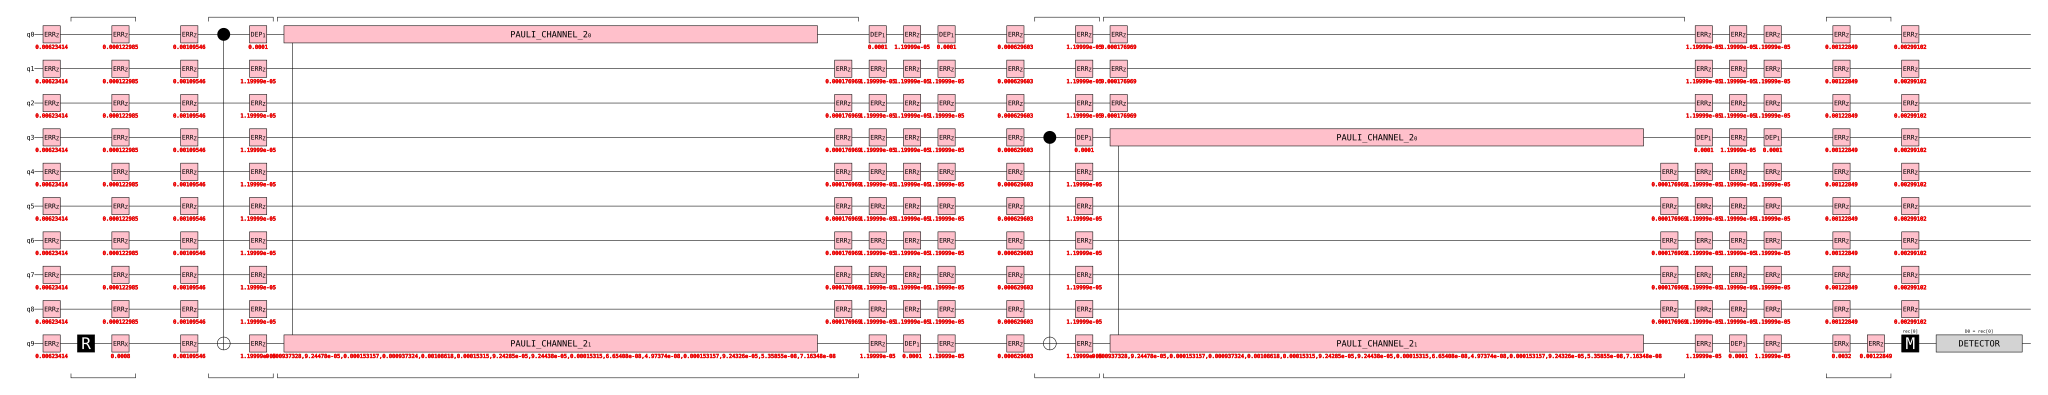

In [3]:
stab0 = slice_stab(circuit, 0, reset_idxs)
print(f'Stab 0 (Z03, weight 2): {len(stab0)} instructions')

diagram = stab0.diagram('timeline-svg')
svg_text = str(diagram)
out_path = DIAGRAMS_DIR / 'weight2_zstab.svg'
out_path.write_text(svg_text, encoding='utf-8')
print(f'Saved: {out_path.relative_to(REPO)}')
display(SVG(svg_text))

## Weight 4 Z-stab (Z1245, 3 番目の stab)

重み 4 の bulk Z stabilizer。`CX 1 9, CX 4 9, CX 2 9, CX 5 9` の 4 連続 (hook error avoidance order: NW→SW→NE→SE)。 weight 2 と比べると CX が 2 倍に増え、トータルの op が大幅に多くなる。

Stab 2 (Z1245, weight 4): 89 instructions
Saved: examples\multi_round\d3_reuse1_3rounds\diagrams\weight4_zstab.svg


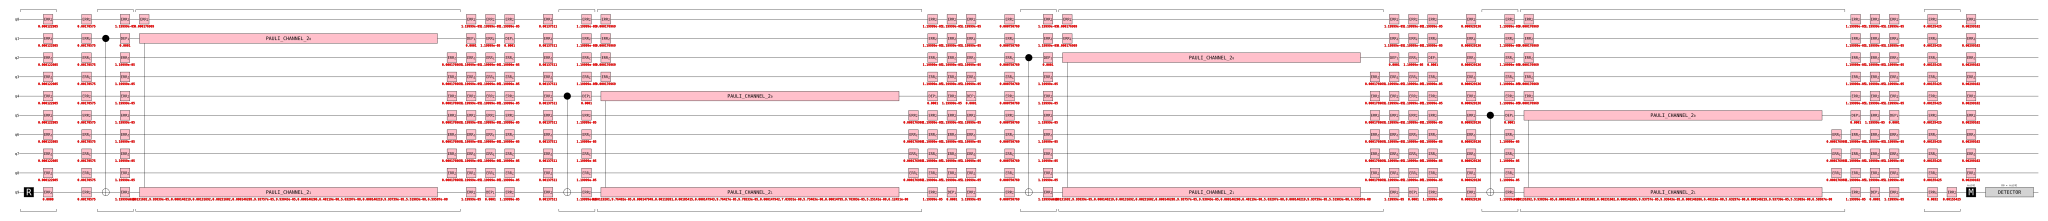

In [4]:
stab2 = slice_stab(circuit, 2, reset_idxs)
print(f'Stab 2 (Z1245, weight 4): {len(stab2)} instructions')

diagram = stab2.diagram('timeline-svg')
svg_text = str(diagram)
out_path = DIAGRAMS_DIR / 'weight4_zstab.svg'
out_path.write_text(svg_text, encoding='utf-8')
print(f'Saved: {out_path.relative_to(REPO)}')
display(SVG(svg_text))

## 補足: SVG ファイルの再生成

上のセルを実行すれば毎回 `examples/multi_round/d3_reuse1_3rounds/diagrams/` 配下の SVG が上書きされる。
circuit を更新したい場合は先に `python experiments/exp_build_examples.py` で `noisy_perop.stim` を再生成してから notebook を再実行。

## 何が読み取れるか (例)
- 各 TICK 区切りに対応する縦線
- `PAULI_CHANNEL_2` (15 個の確率) が MS 直後に挿入されている (CX のところ)
- `Z_ERROR` が idle qubit に並列に置かれている
- 大きな transport-time Z_ERROR (各 anchor 前) が定期的に現れる
- 最終 `M` の直後に `DETECTOR rec[-1]` が出ている